In [25]:
# Cell 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
from sklearn.metrics.pairwise import cosine_similarity

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Libraries imported successfully!")

Libraries imported successfully!


In [26]:
# Cell 2: Set up processed data directory

processed_path = "../processed_data"

print("Processed data directory:", os.path.abspath(processed_path))

print("\nAvailable processed files:")
for file in os.listdir(processed_path):
    print("-", file)

Processed data directory: c:\Users\Shrutee Patil\Desktop\MSC Part 2 Sem 3\Research Project\Spotlight_project\processed_data

Available processed files:
- category_distribution.csv
- creator_popularity.csv
- interactions.csv
- testing_interactions.csv
- training_interactions.csv
- video_creator_groups.csv
- video_creator_map.csv
- video_metadata.csv


In [27]:
# Cell 3: Load required datasets

training_data = pd.read_csv(
    os.path.join(processed_path, "training_interactions.csv")
)

testing_data = pd.read_csv(
    os.path.join(processed_path, "testing_interactions.csv")
)

video_creator_map = pd.read_csv(
    os.path.join(processed_path, "video_creator_map.csv")
)

print("Datasets loaded successfully!")

print("\nTraining data:", training_data.shape)
print("Testing data:", testing_data.shape)
print("Video-creator mapping:", video_creator_map.shape)

Datasets loaded successfully!

Training data: (4387382, 9)
Testing data: (107196, 9)
Video-creator mapping: (3327, 2)


In [28]:
# Cell 4: Validate loaded datasets

print("TRAINING DATA")
print("Unique users:", training_data["user_id"].nunique())
print("Unique videos:", training_data["video_id"].nunique())
print("Missing values:", training_data.isna().sum().sum())

print("\nTESTING DATA")
print("Unique users:", testing_data["user_id"].nunique())
print("Unique videos:", testing_data["video_id"].nunique())
print("Missing values:", testing_data.isna().sum().sum())

print("\nVIDEO-CREATOR MAPPING")
print("Unique videos:", video_creator_map["video_id"].nunique())
print("Unique creators:", video_creator_map["author_id"].nunique())

TRAINING DATA
Unique users: 1411
Unique videos: 3288
Missing values: 0

TESTING DATA
Unique users: 1411
Unique videos: 1162
Missing values: 0

VIDEO-CREATOR MAPPING
Unique videos: 3327
Unique creators: 2031


In [29]:
# Cell 5: Identify videos appearing only in testing

training_videos = set(training_data["video_id"].unique())
testing_videos = set(testing_data["video_id"].unique())

common_videos = training_videos.intersection(testing_videos)
unseen_test_videos = testing_videos - training_videos

print("Training videos:", len(training_videos))
print("Testing videos:", len(testing_videos))
print("Videos present in both:", len(common_videos))
print("Videos appearing only in testing:", len(unseen_test_videos))

print("\nPercentage of test videos unseen during training:",
      round(len(unseen_test_videos) / len(testing_videos) * 100, 2), "%")

Training videos: 3288
Testing videos: 1162
Videos present in both: 1123
Videos appearing only in testing: 39

Percentage of test videos unseen during training: 3.36 %


In [30]:
# Cell 6: Define baseline experiment settings

TOP_K = 10

RANDOM_STATE = 42

# Candidate videos available during training
candidate_videos = sorted(training_videos)

# Users available during training
candidate_users = sorted(training_data["user_id"].unique())

print("Baseline experiment configuration")
print("----------------------------------")
print("Recommendation list size:", TOP_K)
print("Candidate users:", len(candidate_users))
print("Candidate videos:", len(candidate_videos))
print("Random state:", RANDOM_STATE)

Baseline experiment configuration
----------------------------------
Recommendation list size: 10
Candidate users: 1411
Candidate videos: 3288
Random state: 42


In [31]:
# Cell 7: Analyse watch ratio distribution

print("Watch ratio statistics:")
display(training_data["watch_ratio"].describe())

print("\nWatch ratios below zero:",
      (training_data["watch_ratio"] < 0).sum())

print("Watch ratios equal to zero:",
      (training_data["watch_ratio"] == 0).sum())

print("Watch ratios between zero and one:",
      ((training_data["watch_ratio"] > 0) &
       (training_data["watch_ratio"] <= 1)).sum())

print("Watch ratios above one:",
      (training_data["watch_ratio"] > 1).sum())

Watch ratio statistics:


count    4.387382e+06
mean     9.102706e-01
std      1.348511e+00
min      0.000000e+00
25%      4.735927e-01
50%      7.742437e-01
75%      1.124417e+00
max      5.715214e+02
Name: watch_ratio, dtype: float64


Watch ratios below zero: 0
Watch ratios equal to zero: 28357
Watch ratios between zero and one: 2923497
Watch ratios above one: 1435528


In [32]:
# Cell 8: Create capped watch ratio

training_data["preference_score"] = (
    training_data["watch_ratio"].clip(lower=0, upper=1)
)

print("Preference signal created successfully!")

print("\nPreference score statistics:")
display(training_data["preference_score"].describe())

print("\nValues above 1 after capping:",
      (training_data["preference_score"] > 1).sum())

print("Values below 0 after capping:",
      (training_data["preference_score"] < 0).sum())

Preference signal created successfully!

Preference score statistics:


count    4.387382e+06
mean     6.995833e-01
std      3.075442e-01
min      0.000000e+00
25%      4.735927e-01
50%      7.742437e-01
75%      1.000000e+00
max      1.000000e+00
Name: preference_score, dtype: float64


Values above 1 after capping: 0
Values below 0 after capping: 0


In [33]:
# Cell 9: Create user-video interaction matrix

interaction_matrix = training_data.pivot_table(
    index="user_id",
    columns="video_id",
    values="preference_score",
    aggfunc="mean",
    fill_value=0
)

print("Interaction matrix created successfully!")

print("\nMatrix dimensions:", interaction_matrix.shape)

print("\nNumber of users:", interaction_matrix.shape[0])
print("Number of videos:", interaction_matrix.shape[1])

print("\nSample matrix:")
display(interaction_matrix.iloc[:5, :5])

Interaction matrix created successfully!

Matrix dimensions: (1411, 3288)

Number of users: 1411
Number of videos: 3288

Sample matrix:


video_id,103,109,120,122,128
user_id,,,,,
14,0.429126,1.000000,0.728738,0.477810,0.439333
19,0.624466,1.000000,1.000000,0.759092,0.882691
21,1.000000,0.000000,1.000000,0.000000,0.588365
23,0.169223,1.000000,0.247487,0.438669,0.114338
24,0.345049,0.449337,0.802936,0.797411,1.000000


In [34]:
# Cell 10: Calculate cosine similarity between users

user_similarity = cosine_similarity(interaction_matrix)

user_similarity_df = pd.DataFrame(
    user_similarity,
    index=interaction_matrix.index,
    columns=interaction_matrix.index
)

print("User similarity calculated successfully!")

print("\nSimilarity matrix dimensions:", user_similarity_df.shape)

print("\nSample similarity values:")
display(user_similarity_df.iloc[:5, :5])

User similarity calculated successfully!

Similarity matrix dimensions: (1411, 1411)

Sample similarity values:


user_id,14,19,21,23,24
user_id,,,,,
14,1.000000,0.918822,0.914284,0.822601,0.800804
19,0.918822,1.000000,0.940398,0.847073,0.818674
21,0.914284,0.940398,1.000000,0.839079,0.815298
23,0.822601,0.847073,0.839079,1.000000,0.741909
24,0.800804,0.818674,0.815298,0.741909,1.000000


User similarity statistics:


count    994755.000000
mean          0.874466
std           0.054404
min           0.490704
25%           0.846117
50%           0.888322
75%           0.914597
max           0.978064
dtype: float64

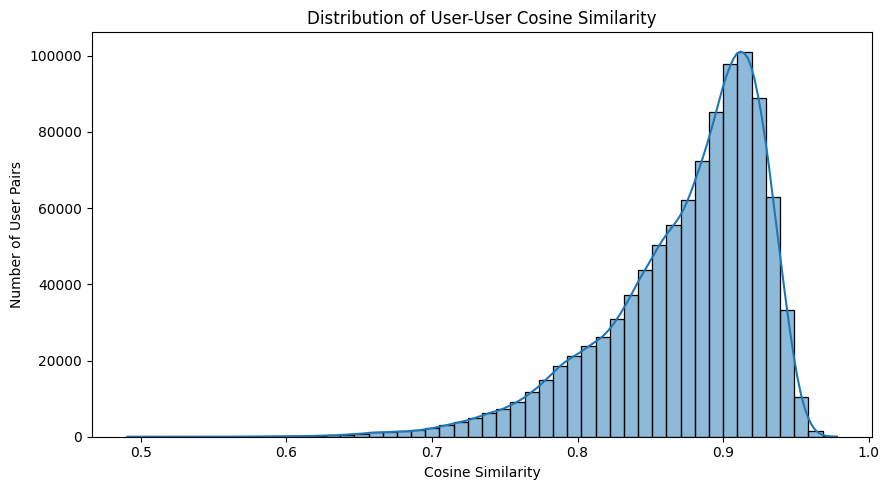

In [35]:
# Cell 11: Analyse user similarity distribution

similarity_values = user_similarity[
    np.triu_indices_from(user_similarity, k=1)
]

print("User similarity statistics:")
display(pd.Series(similarity_values).describe())

plt.figure(figsize=(9, 5))

sns.histplot(
    similarity_values,
    bins=50,
    kde=True
)

plt.title("Distribution of User-User Cosine Similarity")
plt.xlabel("Cosine Similarity")
plt.ylabel("Number of User Pairs")

plt.tight_layout()
plt.show()

In [36]:
# Cell 12: Identify most similar users

target_user = interaction_matrix.index[0]

similar_users = (
    user_similarity_df.loc[target_user]
    .drop(target_user)
    .sort_values(ascending=False)
)

print("Target user:", target_user)

print("\nTop 10 most similar users:")
display(similar_users.head(10).to_frame(name="similarity"))

print("\nLeast similar users:")
display(similar_users.tail(10).to_frame(name="similarity"))

Target user: 14

Top 10 most similar users:


,similarity
user_id,
2118,0.930478
5568,0.930022
5772,0.929893
5888,0.928850
6099,0.928790
1704,0.928282
683,0.928129
2205,0.927820
1944,0.927721



Least similar users:


,similarity
user_id,
1731,0.735765
223,0.730637
4924,0.724996
4479,0.717735
4950,0.713985
1278,0.710720
6111,0.706801
2890,0.698969
3706,0.663796


In [37]:
# Cell 13: Define neighbourhood size

K_NEIGHBORS = 20

print("Collaborative Filtering Configuration")
print("--------------------------------------")
print("Similarity measure: Cosine Similarity")
print("Neighbourhood size:", K_NEIGHBORS)
print("Recommendation list size:", TOP_K)

Collaborative Filtering Configuration
--------------------------------------
Similarity measure: Cosine Similarity
Neighbourhood size: 20
Recommendation list size: 10


In [38]:
# Cell 14: Predict user preferences using nearest neighbours

def predict_user_preferences(user_id, k=K_NEIGHBORS):

    # Get similarities for the target user
    similarities = user_similarity_df.loc[user_id].drop(user_id)

    # Select top K similar users
    nearest_users = similarities.nlargest(k)

    # Retrieve their interaction data
    neighbour_ratings = interaction_matrix.loc[nearest_users.index]

    # Calculate similarity-weighted preference scores
    weighted_scores = np.dot(
        nearest_users.values,
        neighbour_ratings.values
    )

    # Calculate total similarity weight
    similarity_sum = np.abs(nearest_users.values).sum()

    predicted_scores = weighted_scores / similarity_sum

    return pd.Series(
        predicted_scores,
        index=interaction_matrix.columns
    )


print("Prediction function defined successfully!")

Prediction function defined successfully!


In [39]:
# Cell 15: Test predicted preferences for one user

test_user = interaction_matrix.index[0]

predicted_preferences = predict_user_preferences(test_user)

print("Test user:", test_user)
print("Number of predicted video scores:", len(predicted_preferences))

print("\nTop 10 predicted videos:")
display(
    predicted_preferences
    .sort_values(ascending=False)
    .head(10)
    .to_frame(name="predicted_preference")
)

print("\nPrediction score range:")
print("Minimum:", predicted_preferences.min())
print("Maximum:", predicted_preferences.max())

Test user: 14
Number of predicted video scores: 3288

Top 10 predicted videos:


,predicted_preference
video_id,
3597,1.0
183,1.0
7300,1.0
2687,1.0
340,1.0
10062,1.0
1312,1.0
1306,1.0
5252,1.0



Prediction score range:
Minimum: 0.0
Maximum: 1.0000000000000002


In [40]:
# Cell 16: Analyse predicted preference scores

print("Predicted preference statistics:")
display(predicted_preferences.describe())

print("\nNumber of videos with score exactly 1:",
      np.isclose(predicted_preferences, 1.0).sum())

print("Number of videos with score exactly 0:",
      np.isclose(predicted_preferences, 0.0).sum())

print("Number of unique prediction scores:",
      predicted_preferences.nunique())

print("\nTop 20 predicted scores:")
display(
    predicted_preferences
    .sort_values(ascending=False)
    .head(20)
    .to_frame(name="predicted_preference")
)

Predicted preference statistics:


count    3288.000000
mean        0.752069
std         0.246092
min         0.000000
25%         0.667149
50%         0.824454
75%         0.942264
max         1.000000
dtype: float64


Number of videos with score exactly 1: 133
Number of videos with score exactly 0: 2
Number of unique prediction scores: 3137

Top 20 predicted scores:


,predicted_preference
video_id,
3597,1.0
183,1.0
7300,1.0
2687,1.0
340,1.0
10062,1.0
1312,1.0
1306,1.0
5252,1.0


In [41]:
# Cell 17: Generate Top-K recommendations for a user

def recommend_for_user(user_id, k=TOP_K):

    predicted_scores = predict_user_preferences(user_id)

    # Exclude videos already present in training interactions
    watched_videos = set(
        training_data.loc[
            training_data["user_id"] == user_id,
            "video_id"
        ]
    )

    candidate_scores = predicted_scores[
        ~predicted_scores.index.isin(watched_videos)
    ]

    # Deterministic ranking: score descending, video ID ascending
    recommendations = (
        candidate_scores
        .rename("predicted_preference")
        .reset_index()
        .sort_values(
            ["predicted_preference", "video_id"],
            ascending=[False, True],
            kind="mergesort"
        )
        .head(k)
        .reset_index(drop=True)
    )

    return recommendations


print("Recommendation function defined successfully!")

Recommendation function defined successfully!


In [42]:
# Cell 18: Generate recommendations for one user

sample_user = 14

sample_recommendations = recommend_for_user(
    sample_user,
    k=TOP_K
)

print("User ID:", sample_user)
print("\nTop 10 recommended videos:")

display(sample_recommendations)

print("\nNumber of recommendations:",
      len(sample_recommendations))

print("Duplicate recommended videos:",
      sample_recommendations["video_id"].duplicated().sum())

User ID: 14

Top 10 recommended videos:


,video_id,predicted_preference
0,3992,0.997153
1,7263,0.995710
2,835,0.990655
3,6177,0.990421
4,6086,0.966525
5,3141,0.962310
6,3107,0.961977
7,152,0.950126
8,2065,0.949943
9,4268,0.945336



Number of recommendations: 10
Duplicate recommended videos: 0


In [43]:
# Cell 19: Check unseen candidate availability for every user

watched_video_counts = (
    training_data.groupby("user_id")["video_id"]
    .nunique()
)

candidate_counts = len(candidate_videos) - watched_video_counts

candidate_summary = candidate_counts.describe()

print("Unseen candidate videos per user:")
display(candidate_summary)

print("\nUsers with fewer than 10 eligible candidates:",
      (candidate_counts < TOP_K).sum())

print("Minimum eligible candidates:",
      candidate_counts.min())

print("Maximum eligible candidates:",
      candidate_counts.max())

Unseen candidate videos per user:


count    1411.000000
mean      178.586818
std        53.126172
min        49.000000
25%       140.000000
50%       180.000000
75%       217.000000
max       376.000000
Name: video_id, dtype: float64


Users with fewer than 10 eligible candidates: 0
Minimum eligible candidates: 49
Maximum eligible candidates: 376


In [44]:
# Cell 20: Generate Top-10 recommendations for all users

all_recommendations = []

for user_id in candidate_users:

    user_recommendations = recommend_for_user(
        user_id,
        k=TOP_K
    )

    user_recommendations["user_id"] = user_id

    all_recommendations.append(user_recommendations)

baseline_recommendations = pd.concat(
    all_recommendations,
    ignore_index=True
)

# Arrange columns
baseline_recommendations = baseline_recommendations[
    ["user_id", "video_id", "predicted_preference"]
]

print("Baseline recommendation generation completed!")
print("Dataset shape:", baseline_recommendations.shape)

print("\nUnique users:",
      baseline_recommendations["user_id"].nunique())

print("Unique recommended user-video pairs:",
      baseline_recommendations[["user_id", "video_id"]]
      .drop_duplicates().shape[0])

print("\nRecommendations per user:")
display(
    baseline_recommendations.groupby("user_id")
    .size()
    .describe()
)

print("\nSample recommendations:")
display(baseline_recommendations.head(10))

Baseline recommendation generation completed!
Dataset shape: (14110, 3)

Unique users: 1411
Unique recommended user-video pairs: 14110

Recommendations per user:


count    1411.0
mean       10.0
std         0.0
min        10.0
25%        10.0
50%        10.0
75%        10.0
max        10.0
dtype: float64


Sample recommendations:


,user_id,video_id,predicted_preference
0,14,3992,0.997153
1,14,7263,0.995710
2,14,835,0.990655
3,14,6177,0.990421
4,14,6086,0.966525
5,14,3141,0.962310
6,14,3107,0.961977
7,14,152,0.950126
8,14,2065,0.949943
9,14,4268,0.945336


In [45]:
# Cell 21: Prepare ground truth for evaluation

# Keep only test interactions involving videos known during training
eligible_test_data = testing_data[
    testing_data["video_id"].isin(candidate_videos)
].copy()

# Create relevant video sets for each user
ground_truth = (
    eligible_test_data.groupby("user_id")["video_id"]
    .apply(set)
    .to_dict()
)

print("Ground truth preparation completed!")

print("Original test interactions:", len(testing_data))
print("Eligible warm-start test interactions:", len(eligible_test_data))
print("Excluded cold-start test interactions:",
      len(testing_data) - len(eligible_test_data))

print("\nUsers with eligible test interactions:",
      len(ground_truth))

print("Total relevant user-video pairs:",
      sum(len(videos) for videos in ground_truth.values()))

print("\nRelevant test videos per user:")
display(
    eligible_test_data.groupby("user_id")["video_id"]
    .nunique()
    .describe()
)

Ground truth preparation completed!
Original test interactions: 107196
Eligible warm-start test interactions: 55641
Excluded cold-start test interactions: 51555

Users with eligible test interactions: 1411
Total relevant user-video pairs: 55641

Relevant test videos per user:


count    1411.000000
mean       39.433735
std        16.813465
min         4.000000
25%        28.000000
50%        37.000000
75%        48.000000
max       177.000000
Name: video_id, dtype: float64

In [46]:
# Cell 22: Analyse excluded cold-start test interactions

cold_start_test_data = testing_data[
    ~testing_data["video_id"].isin(candidate_videos)
].copy()

print("Cold-start diagnostic summary")
print("--------------------------------")
print("Excluded interactions:", len(cold_start_test_data))
print("Unique cold-start videos:",
      cold_start_test_data["video_id"].nunique())

print("\nInteractions per cold-start video:")
display(
    cold_start_test_data.groupby("video_id")
    .size()
    .describe()
)

print("\nTop 15 cold-start videos by test interaction count:")
display(
    cold_start_test_data.groupby("video_id")
    .size()
    .sort_values(ascending=False)
    .head(15)
    .reset_index(name="test_interactions")
)

print("\nPercentage of test interactions excluded:",
      round(len(cold_start_test_data) / len(testing_data) * 100, 2), "%")

Cold-start diagnostic summary
--------------------------------
Excluded interactions: 51555
Unique cold-start videos: 39

Interactions per cold-start video:


count      39.000000
mean     1321.923077
std        53.169731
min      1159.000000
25%      1290.500000
50%      1338.000000
75%      1361.000000
max      1397.000000
dtype: float64


Top 15 cold-start videos by test interaction count:


,video_id,test_interactions
0,1583,1397
1,7887,1392
2,3290,1372
3,1612,1370
4,10589,1369
5,3307,1368
6,10552,1364
7,9291,1363
8,1565,1361
9,3338,1361



Percentage of test interactions excluded: 48.09 %


In [47]:
# Cell 23: Inspect metadata of cold-start videos

video_metadata = pd.read_csv(
    os.path.join(processed_path, "video_metadata.csv")
)

cold_start_video_ids = cold_start_test_data[
    "video_id"
].unique()

cold_start_metadata = video_metadata[
    video_metadata["video_id"].isin(cold_start_video_ids)
].copy()

print("Metadata columns:")
print(video_metadata.columns.tolist())

print("\nCold-start metadata shape:",
      cold_start_metadata.shape)

print("\nCold-start video metadata:")
display(cold_start_metadata.head(10))

print("\nMissing values in cold-start metadata:")
display(
    cold_start_metadata.isnull().sum()
    .sort_values(ascending=False)
)

Metadata columns:
['video_id', 'category_ids', 'category_count', 'manual_cover_text', 'caption', 'topic_tag', 'first_level_category_id', 'first_level_category_name', 'second_level_category_id', 'second_level_category_name', 'third_level_category_id', 'third_level_category_name']

Cold-start metadata shape: (39, 12)

Cold-start video metadata:


,video_id,category_ids,category_count,manual_cover_text,caption,topic_tag,first_level_category_id,first_level_category_name,second_level_category_id,second_level_category_name,third_level_category_id,third_level_category_name
629,1565,"[11, 6]",2,UNKNOWN,如果你在二环上看到劳斯莱斯排排站 请睁大眼睛看第二辆有石家庄之光伦[机智],[],6.0,明星娱乐,-124.0,UNKNOWN,-124.0,UNKNOWN
631,1579,"[9, 28]",2,UNKNOWN,论广场舞的传染性 @快手粉条(O40300047),[],9.0,喜剧,136.0,喜剧段子,-124.0,UNKNOWN
632,1583,"[28, 9]",2,这是看到啥了,这是看到啥了？把孩子吓成这些 #用快影上热门,[用快影上热门],23.0,时政资讯,683.0,国际时政,-124.0,UNKNOWN
633,1596,[16],1,UNKNOWN,肚子气多老放屁？原因在这里 #健康养生,[健康养生],16.0,健康,179.0,看病治病,1163.0,常见疾病
634,1612,[28],1,UNKNOWN,彩礼不得超1万，喜宴不得超过10桌，婚车不得超过6辆！这事你怎么看？ #结婚 #彩礼,"[彩礼,结婚]",28.0,民生资讯,223.0,社会事件,-124.0,UNKNOWN
635,1622,"[19, 28]",2,UNKNOWN,看了这为爱情凿出的6208级天梯，许多人又相信爱情了！ #真爱 #天梯,"[天梯,真爱]",19.0,情感,744.0,情感关系,2636.0,亲密关系
636,1643,"[9, 28, 25]",3,UNKNOWN,#高清视频 #幼儿园开学翻车现场 睡午觉到底是找爸爸还是找奶奶呢？你俩让妈妈怎么想😂,"[幼儿园开学翻车现场,高清视频]",28.0,民生资讯,223.0,社会事件,2442.0,趣闻趣事
637,1667,[28],1,UNKNOWN,蒙冤入狱9778天，张玉环申请国家赔偿2234万元，要求法院道歉！,[],28.0,民生资讯,223.0,社会事件,1830.0,社会新闻
1190,3288,[28],1,UNKNOWN,#俄罗斯直杀美国家门口！,[俄罗斯直杀美国家门口],35.0,军事,347.0,军事冲突,-124.0,UNKNOWN
1191,3289,[26],1,UNKNOWN,等了好久终于拍到了，火车每次经过大桥都会鸣笛，这是为什么呢？#贵州,[贵州],10.0,旅游,729.0,旅游玩法,2572.0,风景航拍



Missing values in cold-start metadata:


video_id                      0
category_ids                  0
category_count                0
manual_cover_text             0
caption                       0
topic_tag                     0
first_level_category_id       0
first_level_category_name     0
second_level_category_id      0
second_level_category_name    0
third_level_category_id       0
third_level_category_name     0
dtype: int64

In [49]:
# Cell 24A: Inspect column names and merge structure

print("Video-creator mapping columns:")
print(video_creator_map.columns.tolist())

print("\nVideo-creator groups columns:")
print(video_creator_groups.columns.tolist())

print("\nMerged cold-start dataset columns:")
print(cold_start_creator_data.columns.tolist())

print("\nFirst 5 rows of creator mapping:")
display(video_creator_map.head())

print("\nFirst 5 rows of creator groups:")
display(video_creator_groups.head())

Video-creator mapping columns:
['video_id', 'author_id']

Video-creator groups columns:
['video_id', 'author_id', 'average_video_daily_shows', 'creator_group']

Merged cold-start dataset columns:
['video_id', 'category_ids', 'author_id_x', 'author_id_y', 'average_video_daily_shows', 'creator_group']

First 5 rows of creator mapping:


,video_id,author_id
0,103,1862
1,109,1853
2,120,4450
3,122,888
4,128,2269



First 5 rows of creator groups:


,video_id,author_id,average_video_daily_shows,creator_group
0,103,1862,120356.982143,Established
1,109,1853,23561.714286,Emerging
2,120,4450,47238.071429,Established
3,122,888,171880.415179,Established
4,128,2269,488870.392857,Established


In [50]:
# Cell 24: Analyse creator groups of cold-start videos

cold_start_creator_data = (
    cold_start_metadata[["video_id", "category_ids"]]
    .merge(
        video_creator_groups,
        on="video_id",
        how="left"
    )
)

print("Cold-start creator analysis:")
print("Total cold-start videos:",
      cold_start_creator_data["video_id"].nunique())

print("Videos with creator IDs:",
      cold_start_creator_data["author_id"].notna().sum())

print("\nCreator group distribution:")
display(
    cold_start_creator_data["creator_group"]
    .value_counts(dropna=False)
)

print("\nCold-start video and creator details:")
display(cold_start_creator_data.head(15))

Cold-start creator analysis:
Total cold-start videos: 39
Videos with creator IDs: 39

Creator group distribution:


creator_group
Established    26
NaN            12
Emerging        1
Name: count, dtype: int64


Cold-start video and creator details:


,video_id,category_ids,author_id,average_video_daily_shows,creator_group
0,1565,"[11, 6]",4670,1.700000e+01,Emerging
1,1579,"[9, 28]",8307,5.335146e+06,Established
2,1583,"[28, 9]",7396,NaN,NaN
3,1596,[16],7605,3.254130e+05,Established
4,1612,[28],2661,NaN,NaN
5,1622,"[19, 28]",2661,NaN,NaN
6,1643,"[9, 28, 25]",5763,4.695670e+05,Established
7,1667,[28],5201,8.470355e+05,Established
8,3288,[28],6366,NaN,NaN
9,3289,[26],1798,4.214062e+05,Established


In [51]:
# Cell 25: Validate evaluation inputs

recommendation_users = set(
    baseline_recommendations["user_id"].unique()
)

ground_truth_users = set(ground_truth.keys())

print("Recommendation users:", len(recommendation_users))
print("Ground truth users:", len(ground_truth_users))

print("Users in both datasets:",
      len(recommendation_users.intersection(ground_truth_users)))

print("Users missing recommendations:",
      len(ground_truth_users - recommendation_users))

print("Users missing ground truth:",
      len(recommendation_users - ground_truth_users))

assert recommendation_users == ground_truth_users
assert baseline_recommendations.groupby("user_id").size().eq(TOP_K).all()

print("\nEvaluation inputs validated successfully!")

Recommendation users: 1411
Ground truth users: 1411
Users in both datasets: 1411
Users missing recommendations: 0
Users missing ground truth: 0

Evaluation inputs validated successfully!


In [52]:
# Cell 26: Calculate Precision@10

precision_scores = []

for user_id, user_data in baseline_recommendations.groupby("user_id"):

    recommended_videos = set(user_data["video_id"])
    relevant_videos = ground_truth[user_id]

    relevant_recommendations = (
        recommended_videos.intersection(relevant_videos)
    )

    precision = len(relevant_recommendations) / TOP_K

    precision_scores.append({
        "user_id": user_id,
        "precision_at_10": precision
    })

precision_results = pd.DataFrame(precision_scores)

mean_precision = precision_results["precision_at_10"].mean()

print("Precision@10 evaluation completed!")
print("Mean Precision@10:", round(mean_precision, 6))
print("Percentage:", round(mean_precision * 100, 2), "%")

print("\nPrecision@10 distribution:")
display(precision_results["precision_at_10"].describe())

print("\nSample user-level precision scores:")
display(precision_results.head(10))

Precision@10 evaluation completed!
Mean Precision@10: 0.139405
Percentage: 13.94 %

Precision@10 distribution:


count    1411.000000
mean        0.139405
std         0.134241
min         0.000000
25%         0.000000
50%         0.100000
75%         0.200000
max         0.700000
Name: precision_at_10, dtype: float64


Sample user-level precision scores:


,user_id,precision_at_10
0,14,0.1
1,19,0.1
2,21,0.3
3,23,0.1
4,24,0.0
5,36,0.0
6,37,0.0
7,41,0.2
8,51,0.2
9,55,0.3


In [53]:
# Cell 27: Calculate Recall@10

recall_scores = []

for user_id, user_data in baseline_recommendations.groupby("user_id"):

    recommended_videos = set(user_data["video_id"])
    relevant_videos = ground_truth[user_id]

    relevant_recommendations = (
        recommended_videos.intersection(relevant_videos)
    )

    recall = len(relevant_recommendations) / len(relevant_videos)

    recall_scores.append({
        "user_id": user_id,
        "recall_at_10": recall
    })

recall_results = pd.DataFrame(recall_scores)

mean_recall = recall_results["recall_at_10"].mean()

print("Recall@10 evaluation completed!")
print("Mean Recall@10:", round(mean_recall, 6))
print("Percentage:", round(mean_recall * 100, 2), "%")

print("\nRecall@10 distribution:")
display(recall_results["recall_at_10"].describe())

print("\nSample user-level recall scores:")
display(recall_results.head(10))

Recall@10 evaluation completed!
Mean Recall@10: 0.03737
Percentage: 3.74 %

Recall@10 distribution:


count    1411.000000
mean        0.037370
std         0.038380
min         0.000000
25%         0.000000
50%         0.031250
75%         0.055556
max         0.333333
Name: recall_at_10, dtype: float64


Sample user-level recall scores:


,user_id,recall_at_10
0,14,0.025641
1,19,0.020833
2,21,0.107143
3,23,0.250000
4,24,0.000000
5,36,0.000000
6,37,0.000000
7,41,0.040000
8,51,0.040816
9,55,0.078947


In [54]:
# Cell 28: Calculate NDCG@10

ndcg_scores = []

for user_id, user_data in baseline_recommendations.groupby("user_id"):

    # Ensure recommendations are in ranked order
    ranked_recommendations = user_data.sort_values(
        ["predicted_preference", "video_id"],
        ascending=[False, True]
    )

    relevant_videos = ground_truth[user_id]

    dcg = 0.0

    for rank, video_id in enumerate(
        ranked_recommendations["video_id"], start=1
    ):
        if video_id in relevant_videos:
            dcg += 1 / np.log2(rank + 1)

    # Ideal DCG: all relevant videos placed at the top
    ideal_relevant_count = min(len(relevant_videos), TOP_K)

    idcg = sum(
        1 / np.log2(rank + 1)
        for rank in range(1, ideal_relevant_count + 1)
    )

    ndcg = dcg / idcg if idcg > 0 else 0

    ndcg_scores.append({
        "user_id": user_id,
        "ndcg_at_10": ndcg
    })

ndcg_results = pd.DataFrame(ndcg_scores)

mean_ndcg = ndcg_results["ndcg_at_10"].mean()

print("NDCG@10 evaluation completed!")
print("Mean NDCG@10:", round(mean_ndcg, 6))
print("Percentage:", round(mean_ndcg * 100, 2), "%")

print("\nNDCG@10 distribution:")
display(ndcg_results["ndcg_at_10"].describe())

print("\nSample user-level NDCG scores:")
display(ndcg_results.head(10))

NDCG@10 evaluation completed!
Mean NDCG@10: 0.13941
Percentage: 13.94 %

NDCG@10 distribution:


count    1411.000000
mean        0.139410
std         0.143360
min         0.000000
25%         0.000000
50%         0.094788
75%         0.220092
max         0.793584
Name: ndcg_at_10, dtype: float64


Sample user-level NDCG scores:


,user_id,ndcg_at_10
0,14,0.078398
1,19,0.073364
2,21,0.297272
3,23,0.151020
4,24,0.000000
5,36,0.000000
6,37,0.000000
7,41,0.217261
8,51,0.212226
9,55,0.359710


In [55]:
# Cell 29: Calculate Hit Rate@10

hit_scores = []

for user_id, user_data in baseline_recommendations.groupby("user_id"):

    recommended_videos = set(user_data["video_id"])
    relevant_videos = ground_truth[user_id]

    hits = recommended_videos.intersection(relevant_videos)

    hit_scores.append({
        "user_id": user_id,
        "hit_rate_at_10": int(len(hits) > 0)
    })

hit_results = pd.DataFrame(hit_scores)

mean_hit_rate = hit_results["hit_rate_at_10"].mean()

print("Hit Rate@10 evaluation completed!")
print("Mean Hit Rate@10:", round(mean_hit_rate, 6))
print("Percentage of users with at least one relevant recommendation:",
      round(mean_hit_rate * 100, 2), "%")

print("\nHit Rate distribution:")
display(hit_results["hit_rate_at_10"].value_counts().rename(
    index={0: "No relevant recommendations", 1: "At least one relevant recommendation"}
))

Hit Rate@10 evaluation completed!
Mean Hit Rate@10: 0.696669
Percentage of users with at least one relevant recommendation: 69.67 %

Hit Rate distribution:


hit_rate_at_10
At least one relevant recommendation    983
No relevant recommendations             428
Name: count, dtype: int64

In [56]:
# Cell 30: Consolidate baseline evaluation metrics

baseline_metrics = pd.DataFrame({
    "Metric": [
        "Precision@10",
        "Recall@10",
        "NDCG@10",
        "Hit Rate@10"
    ],
    "Score": [
        mean_precision,
        mean_recall,
        mean_ndcg,
        mean_hit_rate
    ]
})

baseline_metrics["Percentage"] = (
    baseline_metrics["Score"] * 100
).round(2)

display(baseline_metrics)

print("\nBaseline evaluation summary:")
for _, row in baseline_metrics.iterrows():
    print(f"{row['Metric']}: {row['Score']:.4f} ({row['Percentage']:.2f}%)")

,Metric,Score,Percentage
0,Precision@10,0.139405,13.94
1,Recall@10,0.037370,3.74
2,NDCG@10,0.139410,13.94
3,Hit Rate@10,0.696669,69.67



Baseline evaluation summary:
Precision@10: 0.1394 (13.94%)
Recall@10: 0.0374 (3.74%)
NDCG@10: 0.1394 (13.94%)
Hit Rate@10: 0.6967 (69.67%)


In [57]:
# Cell 31: Calculate catalogue coverage

recommended_unique_videos = baseline_recommendations["video_id"].nunique()

total_candidate_videos = len(candidate_videos)

catalogue_coverage = (
    recommended_unique_videos / total_candidate_videos
)

print("Catalogue Coverage Analysis")
print("----------------------------")

print("Available candidate videos:", total_candidate_videos)
print("Unique videos recommended:", recommended_unique_videos)

print("Catalogue Coverage:",
      round(catalogue_coverage, 4))

print("Catalogue Coverage Percentage:",
      round(catalogue_coverage * 100, 2), "%")

Catalogue Coverage Analysis
----------------------------
Available candidate videos: 3288
Unique videos recommended: 1234
Catalogue Coverage: 0.3753
Catalogue Coverage Percentage: 37.53 %


In [58]:
# Cell 32: Compare Emerging vs Established creator exposure

# Creator-group information for the eligible catalogue
catalogue_group_data = (
    video_creator_groups[
        ["video_id", "author_id", "creator_group"]
    ]
    .drop_duplicates("video_id")
)

catalogue_group_data = catalogue_group_data[
    catalogue_group_data["video_id"].isin(candidate_videos)
]

# Creator-group information for baseline recommendations
baseline_group_data = baseline_recommendations.merge(
    video_creator_groups[
        ["video_id", "author_id", "creator_group"]
    ].drop_duplicates("video_id"),
    on="video_id",
    how="left"
)

# Catalogue representation
catalogue_distribution = (
    catalogue_group_data["creator_group"]
    .value_counts()
)

catalogue_percentage = (
    catalogue_distribution / catalogue_distribution.sum() * 100
)

# Recommendation exposure
exposure_distribution = (
    baseline_group_data["creator_group"]
    .value_counts()
)

exposure_percentage = (
    exposure_distribution / exposure_distribution.sum() * 100
)

# Unique recommended videos per group
unique_recommended_videos = (
    baseline_group_data.groupby("creator_group")["video_id"]
    .nunique()
)

# Unique creators represented per group
unique_recommended_creators = (
    baseline_group_data.groupby("creator_group")["author_id"]
    .nunique()
)

# Combine results
creator_exposure_analysis = pd.DataFrame({
    "Catalogue_Videos": catalogue_distribution,
    "Catalogue_Percentage": catalogue_percentage,
    "Recommendation_Exposure": exposure_distribution,
    "Exposure_Percentage": exposure_percentage,
    "Unique_Recommended_Videos": unique_recommended_videos,
    "Unique_Recommended_Creators": unique_recommended_creators
})

creator_exposure_analysis["Exposure_Ratio"] = (
    creator_exposure_analysis["Exposure_Percentage"] /
    creator_exposure_analysis["Catalogue_Percentage"]
)

creator_exposure_analysis = creator_exposure_analysis.round(4)

display(creator_exposure_analysis)

print("\nCreator Exposure Analysis Completed.")

,Catalogue_Videos,Catalogue_Percentage,Recommendation_Exposure,Exposure_Percentage,Unique_Recommended_Videos,Unique_Recommended_Creators,Exposure_Ratio
creator_group,,,,,,,
Emerging,554,16.8491,3678,26.0666,278,262,1.5471
Established,2734,83.1509,10432,73.9334,956,624,0.8891



Creator Exposure Analysis Completed.


In [59]:
# Cell 33: Creator-level exposure concentration analysis

# Eligible creator catalogue
eligible_creator_catalogue = (
    catalogue_group_data[["author_id", "creator_group"]]
    .drop_duplicates()
)

# Total recommendation exposure per creator
creator_exposure_counts = (
    baseline_group_data.groupby("author_id")
    .size()
    .reset_index(name="recommendation_count")
)

# Merge exposure counts into the complete creator catalogue
creator_exposure_analysis_detail = (
    eligible_creator_catalogue.merge(
        creator_exposure_counts,
        on="author_id",
        how="left"
    )
)

# Creators with no recommendations receive zero exposure
creator_exposure_analysis_detail["recommendation_count"] = (
    creator_exposure_analysis_detail["recommendation_count"]
    .fillna(0)
    .astype(int)
)


# Gini coefficient function
def calculate_gini(values):

    values = np.array(values, dtype=float)

    if len(values) == 0:
        return np.nan

    if np.all(values == 0):
        return 0.0

    values = np.sort(values)

    n = len(values)

    cumulative_sum = np.cumsum(values)

    return (
        2 * np.sum((np.arange(1, n + 1) * values))
        / (n * np.sum(values))
        - (n + 1) / n
    )


# Group-level creator exposure statistics
creator_level_metrics = []

for group, data in creator_exposure_analysis_detail.groupby("creator_group"):

    exposure = data["recommendation_count"]

    total_creators = len(data)

    creators_recommended = (exposure > 0).sum()

    creators_zero_exposure = (exposure == 0).sum()

    creator_level_metrics.append({
        "Creator_Group": group,
        "Total_Creators": total_creators,
        "Creators_Recommended": creators_recommended,
        "Creators_Zero_Exposure": creators_zero_exposure,
        "Creator_Coverage_Percentage": (
            creators_recommended / total_creators * 100
        ),
        "Average_Exposure_Per_Creator": exposure.mean(),
        "Median_Exposure_Per_Creator": exposure.median(),
        "Maximum_Creator_Exposure": exposure.max(),
        "Exposure_Gini": calculate_gini(exposure)
    })


creator_level_exposure = pd.DataFrame(creator_level_metrics)

creator_level_exposure = creator_level_exposure.round(4)

display(creator_level_exposure)

print("\nCreator-level exposure concentration analysis completed.")

,Creator_Group,Total_Creators,Creators_Recommended,Creators_Zero_Exposure,Creator_Coverage_Percentage,Average_Exposure_Per_Creator,Median_Exposure_Per_Creator,Maximum_Creator_Exposure,Exposure_Gini
0,Emerging,504,262,242,51.9841,7.2976,1.0,126,0.7841
1,Established,1515,624,891,41.1881,6.8858,0.0,342,0.8659



Creator-level exposure concentration analysis completed.


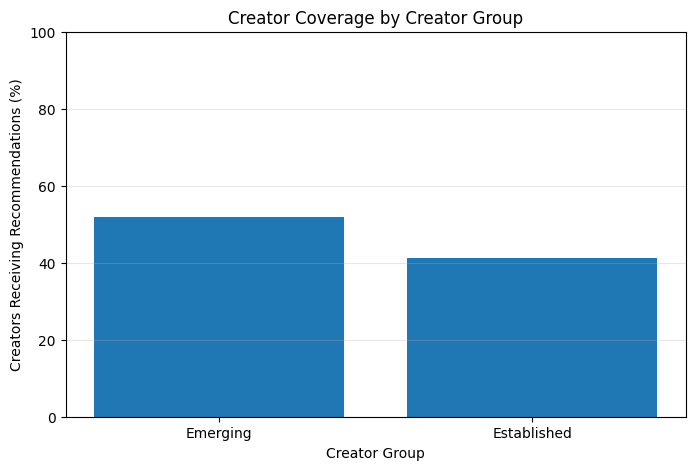

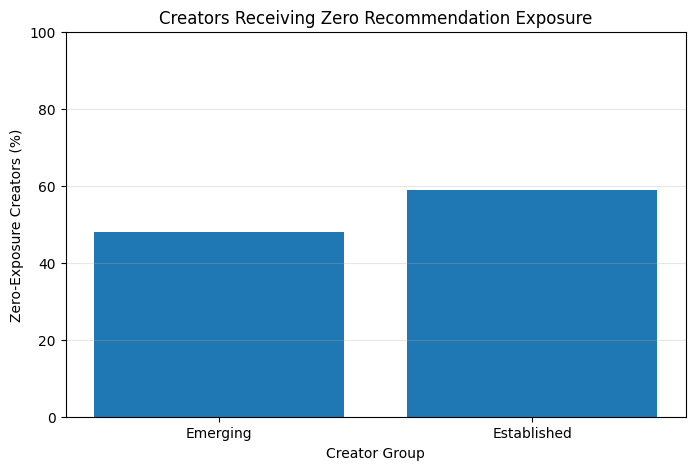

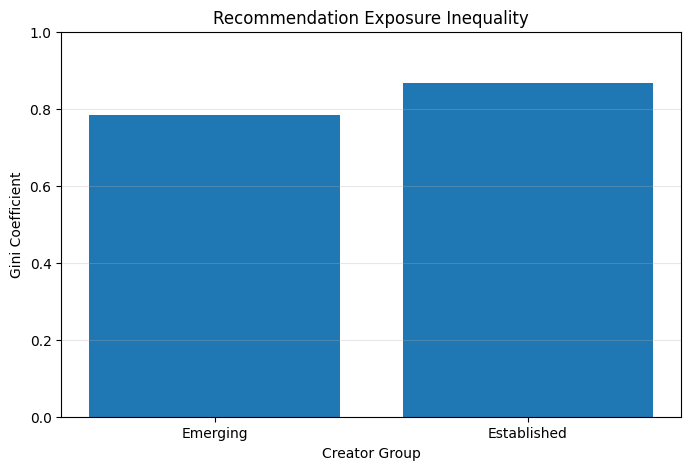

In [60]:
# Cell 34: Visualize creator-level fairness

groups = creator_level_exposure["Creator_Group"]

# 1. Creator Coverage
plt.figure(figsize=(8, 5))

plt.bar(
    groups,
    creator_level_exposure["Creator_Coverage_Percentage"]
)

plt.title("Creator Coverage by Creator Group")
plt.ylabel("Creators Receiving Recommendations (%)")
plt.xlabel("Creator Group")

plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.show()


# 2. Zero Exposure Percentage
zero_exposure_percentage = (
    creator_level_exposure["Creators_Zero_Exposure"] /
    creator_level_exposure["Total_Creators"] * 100
)

plt.figure(figsize=(8, 5))

plt.bar(
    groups,
    zero_exposure_percentage
)

plt.title("Creators Receiving Zero Recommendation Exposure")
plt.ylabel("Zero-Exposure Creators (%)")
plt.xlabel("Creator Group")

plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.show()


# 3. Exposure Inequality (Gini Coefficient)
plt.figure(figsize=(8, 5))

plt.bar(
    groups,
    creator_level_exposure["Exposure_Gini"]
)

plt.title("Recommendation Exposure Inequality")
plt.ylabel("Gini Coefficient")
plt.xlabel("Creator Group")

plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [61]:
# Cell 35: Save baseline results

results_path = "../results"

os.makedirs(results_path, exist_ok=True)

# 1. Ranking metrics
baseline_metrics.to_csv(
    os.path.join(results_path, "baseline_ranking_metrics.csv"),
    index=False
)

# 2. Catalogue coverage
baseline_catalogue_coverage = pd.DataFrame({
    "Total_Candidate_Videos": [total_candidate_videos],
    "Unique_Recommended_Videos": [recommended_unique_videos],
    "Catalogue_Coverage": [catalogue_coverage],
    "Catalogue_Coverage_Percentage": [catalogue_coverage * 100]
})

baseline_catalogue_coverage.to_csv(
    os.path.join(results_path, "baseline_catalogue_coverage.csv"),
    index=False
)

# 3. Group-level exposure analysis
creator_exposure_analysis.to_csv(
    os.path.join(results_path, "baseline_group_exposure.csv")
)

# 4. Creator-level exposure metrics
creator_level_exposure.to_csv(
    os.path.join(results_path, "baseline_creator_level_metrics.csv"),
    index=False
)

# 5. Individual creator exposure details
creator_exposure_analysis_detail.to_csv(
    os.path.join(results_path, "baseline_creator_exposure_detail.csv"),
    index=False
)

# 6. Full recommendation lists
baseline_recommendations.to_csv(
    os.path.join(results_path, "baseline_recommendations.csv"),
    index=False
)

print("Baseline results saved successfully!")
print("\nSaved files:")
for file in os.listdir(results_path):
    print("-", file)

Baseline results saved successfully!

Saved files:
- baseline_catalogue_coverage.csv
- baseline_creator_exposure_detail.csv
- baseline_creator_level_metrics.csv
- baseline_group_exposure.csv
- baseline_ranking_metrics.csv
- baseline_recommendations.csv


In [62]:
# Cell 36: Verify saved baseline results

expected_files = [
    "baseline_catalogue_coverage.csv",
    "baseline_creator_exposure_detail.csv",
    "baseline_creator_level_metrics.csv",
    "baseline_group_exposure.csv",
    "baseline_ranking_metrics.csv",
    "baseline_recommendations.csv"
]

print("Baseline Results Validation")
print("=" * 40)

for file in expected_files:

    file_path = os.path.join(results_path, file)

    if os.path.exists(file_path):

        verification_data = pd.read_csv(file_path)

        print(f"\n✓ {file}")
        print("  Shape:", verification_data.shape)
        print("  Read successfully:", True)

    else:
        print(f"\n✗ {file} — Missing")

print("\nBaseline result validation completed.")

Baseline Results Validation

✓ baseline_catalogue_coverage.csv
  Shape: (1, 4)
  Read successfully: True

✓ baseline_creator_exposure_detail.csv
  Shape: (2019, 3)
  Read successfully: True

✓ baseline_creator_level_metrics.csv
  Shape: (2, 9)
  Read successfully: True

✓ baseline_group_exposure.csv
  Shape: (2, 8)
  Read successfully: True

✓ baseline_ranking_metrics.csv
  Shape: (4, 3)
  Read successfully: True

✓ baseline_recommendations.csv
  Shape: (14110, 3)
  Read successfully: True

Baseline result validation completed.


# Notebook 02 — Baseline Recommender: User-Based Collaborative Filtering

## 1. Objective

The objective of this notebook was to develop a conventional User-Based Collaborative Filtering (User-CF) recommendation system to establish a baseline against which the proposed Spotlight recommendation framework can be evaluated.

The baseline recommends videos based on the preferences of users with similar historical interaction patterns, without incorporating creator-fairness constraints or interest-constrained exploration mechanisms.

---

## 2. Methodology

### Data Preparation
- Used the temporally partitioned training and testing interaction datasets established during data exploration.
- Restricted the recommendation candidate catalogue to videos present in the training data.
- Excluded videos already interacted with by the target user from their recommendation list.
- Used watch ratio as the implicit preference signal, clipping values to the range [0, 1] to prevent extreme watch ratios from disproportionately influencing preference estimates.

### User Preference Representation
Constructed a user-video interaction matrix where rows represent users, columns represent videos, and values represent the clipped watch-ratio preference scores.

Missing interactions were represented as zero. These zeros indicate the absence of a recorded interaction in the constructed matrix and should not be interpreted as explicit negative feedback.

### Similarity Computation
Computed pairwise user similarity using cosine similarity over the interaction matrix.

For each target user, the 20 most similar users were selected as neighbours.

### Preference Prediction
Predicted preference scores were calculated using a similarity-weighted average of the selected neighbours' preference scores.

### Recommendation Generation
Generated a Top-10 recommendation list for each user by ranking candidate videos according to predicted preference scores. Ties were resolved deterministically using video IDs in ascending order.

---

## 3. Evaluation Methodology

The recommender was evaluated using the temporal training-testing split established in Notebook 01.

Only test interactions corresponding to videos available in the training catalogue were considered relevant for the warm-start baseline evaluation.

The following ranking metrics were calculated:

- **Precision@10:** Proportion of recommended videos that were relevant.
- **Recall@10:** Proportion of relevant test videos retrieved within the Top-10 recommendations.
- **NDCG@10:** Ranking quality considering the position of relevant recommendations.
- **Hit Rate@10:** Proportion of users receiving at least one relevant recommendation.

Catalogue coverage and creator-level exposure metrics were additionally calculated to evaluate recommendation distribution beyond user-level relevance.

---

## 4. Baseline Ranking Performance

| Metric | Score |
|---|---:|
| Precision@10 | 0.139405 |
| Recall@10 | 0.037370 |
| NDCG@10 | 0.139410 |
| Hit Rate@10 | 0.696669 |

The baseline achieved a Hit Rate@10 of approximately 69.67%, indicating that a majority of users received at least one recommendation matching their eligible test interactions.

The mean Precision@10 was approximately 13.94%, while Recall@10 was approximately 3.74%.

---

## 5. Catalogue Coverage

The recommender generated 14,110 recommendation slots across 1,411 users.

| Metric | Result |
|---|---:|
| Candidate videos | 3,288 |
| Unique videos recommended | 1,234 |
| Catalogue coverage | 37.53% |

Approximately 37.53% of the candidate catalogue appeared at least once across the recommendation lists. The remaining videos were not recommended by the baseline.

---

## 6. Creator-Level Exposure Analysis

### Group-Level Exposure

| Creator Group | Catalogue Share | Recommendation Exposure | Exposure Ratio |
|---|---:|---:|---:|
| Emerging | 16.85% | 26.07% | 1.5471 |
| Established | 83.15% | 73.93% | 0.8891 |

Emerging creators received a larger share of recommendation exposure than their proportion of the eligible catalogue. Their exposure ratio of approximately 1.55 indicates that their aggregate recommendation exposure was higher than their catalogue representation.

This finding demonstrates that the conventional baseline did not exhibit aggregate exposure disadvantage for Emerging creators under the current experimental setup.

### Individual Creator Exposure

| Metric | Emerging | Established |
|---|---:|---:|
| Total creators | 504 | 1,515 |
| Creators receiving recommendations | 262 | 624 |
| Creators receiving zero exposure | 242 | 891 |
| Creator coverage | 51.98% | 41.19% |
| Average exposure per creator | 7.30 | 6.89 |
| Median exposure per creator | 1 | 0 |
| Maximum exposure | 126 | 342 |
| Exposure Gini coefficient | 0.7841 | 0.8659 |

Despite Emerging creators receiving higher aggregate exposure and creator coverage, recommendation exposure remained highly concentrated within both groups.

Approximately 48.02% of Emerging creators and 58.81% of Established creators received zero recommendations.

The exposure Gini coefficients indicate substantial inequality in recommendation exposure within both creator groups, with greater measured concentration among Established creators.

---

## 7. Key Research Findings

The baseline analysis established the following observations:

1. Aggregate Emerging creator exposure exceeded their catalogue representation.
2. Emerging creators exhibited higher creator coverage than Established creators.
3. A substantial proportion of creators in both groups received no recommendation exposure.
4. Recommendation exposure remained concentrated among a subset of creators.
5. Aggregate creator-group exposure and individual creator-level exposure represent different dimensions of fairness and should not be treated as interchangeable.

These observations suggest that creator fairness should be examined at both group and individual creator levels rather than relying exclusively on aggregate exposure shares.

---

## 8. Limitations

- The baseline relies on collaborative interaction patterns and does not explicitly represent user interests through content categories.
- Videos absent from the training catalogue cannot be recommended by the conventional warm-start baseline.
- The warm-start evaluation excludes test interactions involving videos unseen during training.
- Recommendation exposure is measured using recommendation-slot counts and does not represent actual impressions, clicks, or consumption.
- Creator popularity classification is based on the dataset's available historical exposure metadata and the operational definition established in Notebook 01.
- The baseline does not explicitly optimize creator exposure fairness or encourage exploration.

---

## 9. Research Implication for Spotlight

The findings suggest that improving Emerging creator exposure alone may not adequately address creator-level exposure inequality.

Although Emerging creators collectively receive a disproportionate share of baseline recommendations, many individual Emerging creators remain undiscovered by the recommendation system.

Spotlight therefore investigates whether interest-constrained exploration and creator-aware recommendation mechanisms can distribute exposure opportunities more effectively across creators while preserving personalised relevance.

The baseline established in this notebook will serve as the reference system for subsequent model comparisons.

---

## 10. Outputs Saved

The following experimental outputs were saved and validated:

- `baseline_ranking_metrics.csv`
- `baseline_catalogue_coverage.csv`
- `baseline_group_exposure.csv`
- `baseline_creator_level_metrics.csv`
- `baseline_creator_exposure_detail.csv`
- `baseline_recommendations.csv`

All six files were successfully verified and read back from disk.

---

## Conclusion

The User-Based Collaborative Filtering baseline establishes a conventional personalised recommendation benchmark for the Spotlight research project.

The baseline demonstrates that aggregate Emerging creator exposure can exceed catalogue representation while individual creator exposure remains highly concentrated.

This distinction motivates the investigation of interest-constrained, creator-aware exploration as a potential approach to improving individual creator exposure opportunities without compromising recommendation relevance.
